In [ ]:
import pandas as pd
import numpy as np
import os

# Ingest and aggregating Daily Vegetables Price

In [ ]:
price_files = [
    'veg_prices_2023.csv',
    'veg_prices_2024.csv',
    'veg_prices_2025.csv',
    'veg_prices_2026.csv'
]

df_list = []
for file in price_files:
    if os.path.exists(file):
        df_temp = pd.read_csv(file, low_memory=False)
        df_list.append(df_temp)
        print(f"   ✅ Loaded '{file}' ({len(df_temp):,} rows)")
    else:
        print(f"   ⚠️ Warning: File '{file}' not found. Skipping.")

if not df_list:
    raise FileNotFoundError("❌ No vegetable price files found to process!")

df_prices = pd.concat(df_list, ignore_index=True)

# Normalize column headers if Malay names exist
column_mapping = {'tarikh': 'date', 'negeri': 'state', 'harga': 'price', 'barang': 'item'}
df_prices = df_prices.rename(columns=column_mapping)

# FIX 1: Parse dates safely & drop corrupted rows
df_prices['date'] = pd.to_datetime(df_prices['date'], errors='coerce')
df_prices = df_prices.dropna(subset=['date'])

# FIX 2: Coerce invalid text values in price column to NaN and drop them
df_prices['price'] = pd.to_numeric(df_prices['price'], errors='coerce')
df_prices = df_prices.dropna(subset=['price'])

# Standardize text columns
df_prices['state'] = df_prices['state'].astype(str).str.strip().str.title()
df_prices['item'] = df_prices['item'].astype(str).str.strip().str.upper()

# Filter strictly for target timeframe (2023 to current 2026)
df_prices = df_prices[(df_prices['date'].dt.year >= 2023) & (df_prices['date'].dt.year <= 2026)]

# Group daily premise readings by date, state, and item to get daily average price
print("   🔄 Grouping premise-level records to state-level daily average prices...")
df_prices_daily = df_prices.groupby(['date', 'state', 'item'], as_index=False)['price'].mean()
df_prices_daily.rename(columns={'price': 'avg_price_rm'}, inplace=True)

print(f"   ✅ Aggregated price matrix shape: {df_prices_daily.shape[0]:,} rows")

   ✅ Loaded 'veg_prices_2023.csv' (756,978 rows)
   ✅ Loaded 'veg_prices_2024.csv' (840,731 rows)
   ✅ Loaded 'veg_prices_2025.csv' (973,603 rows)
   ✅ Loaded 'veg_prices_2026.csv' (1,159,777 rows)
   🔄 Grouping premise-level records to state-level daily average prices...
   ✅ Aggregated price matrix shape: 82,632 rows


In [ ]:
items_to_keep = [
    'TOMATO',
    'SAWI HIJAU',
    'CILI MERAH - KULAI',
    'CILI MERAH - MINYAK'
]

df_prices_daily = df_prices_daily[
    df_prices_daily['item'].isin(items_to_keep)
]

In [ ]:
df_prices_daily.head()


,date,state,item,avg_price_rm
0,2023-01-01,Johor,CILI MERAH - KULAI,16.134844
1,2023-01-01,Johor,CILI MERAH - MINYAK,15.069778
2,2023-01-01,Johor,SAWI HIJAU,7.378652
3,2023-01-01,Johor,TOMATO,7.295278
4,2023-01-01,Kedah,CILI MERAH - KULAI,17.712973


In [ ]:
df_prices_daily.tail()

,date,state,item,avg_price_rm
82626,2026-09-08,W.P. Labuan,TOMATO,9.616667
82627,2026-09-08,W.P. Putrajaya,CILI MERAH - KULAI,13.177273
82628,2026-09-08,W.P. Putrajaya,CILI MERAH - MINYAK,16.500000
82629,2026-09-08,W.P. Putrajaya,SAWI HIJAU,6.862222
82631,2026-09-08,W.P. Putrajaya,TOMATO,9.389333


In [ ]:
import pandas as pd

# Check exact counts of available records per item keyword
items_of_interest = ['CILI MERAH - KULAI', 'TOMATO', 'SAWI', 'CILI MERAH - MINYAK']

# Filter dataset for target crops
df_filtered = df_prices_daily[df_prices_daily['item'].str.contains('|'.join(items_of_interest), na=False)]

# 1. Total Raw Price Records per Crop
record_counts = df_filtered['item'].value_counts().reset_index()
record_counts.columns = ['Vegetable Item', 'Total Raw Price Records']
display(record_counts)

# 2. Daily & State Continuity Check (Unique Dates covered per Crop)
date_coverage = df_filtered.groupby('item').agg(
    start_date=('date', 'min'),
    end_date=('date', 'max'),
    unique_days=('date', 'nunique'),
    unique_states=('state', 'nunique')
).reset_index()

display(date_coverage)

,Vegetable Item,Total Raw Price Records
0,TOMATO,19718
1,SAWI HIJAU,19662
2,CILI MERAH - KULAI,18434
3,CILI MERAH - MINYAK,17534


,item,start_date,end_date,unique_days,unique_states
0,CILI MERAH - KULAI,2023-01-01,2026-09-08,1258,18
1,CILI MERAH - MINYAK,2023-01-01,2026-09-08,1261,18
2,SAWI HIJAU,2023-01-01,2026-09-08,1264,17
3,TOMATO,2023-01-01,2026-09-08,1264,18


Check null values

In [ ]:
percentage_values_count= df_prices_daily.isnull().sum()
percentage_missing_value = (
    percentage_values_count / len(df_prices_daily)
* 100
    )
missing_summary= pd.DataFrame({
    'Missing Count': percentage_values_count,
    'Missing Percentage': percentage_missing_value
    })
missing_summary.sort_values('Missing Percentage', ascending=False)
print(missing_summary)
print("Dimension of data: ", df_prices_daily.shape)
print ("Size of dataset: ",df_prices_daily.size )


              Missing Count  Missing Percentage
date                      0                 0.0
state                     0                 0.0
item                      0                 0.0
avg_price_rm              0                 0.0
Dimension of data:  (75348, 4)
Size of dataset:  301392


# Upsample weekly diesel prices change to daily (step-hold)

In [ ]:
# Load weekly fuel data (OpenDOSM format)
df_diesel = pd.read_csv('weekly_diesel_price.csv')
df_diesel['date'] = pd.to_datetime(df_diesel['date'])
df_diesel = df_diesel.sort_values('date')

# Generate complete continuous daily date framework (2023-01-01 to 2026-09-30)
min_date = pd.to_datetime("2023-01-01")
max_date = df_prices_daily['date'].max()
full_date_range = pd.date_range(start=min_date, end=max_date, freq='D')

# Create master daily grid for diesel
df_diesel_daily = pd.DataFrame({'date': full_date_range})
df_diesel_daily = df_diesel_daily.merge(df_diesel[['date', 'diesel']], on='date', how='left')

# Forward fill (Step-Hold) weekly rates across all days of the week
df_diesel_daily['diesel'] = df_diesel_daily['diesel'].ffill().bfill()
df_diesel_daily.rename(columns={'diesel': 'change_in_diesel_price_rm'}, inplace=True)
print("   ✅ Upsampling complete (Weekly -> Daily Forward-Fill applied).")

   ✅ Upsampling complete (Weekly -> Daily Forward-Fill applied).


In [ ]:
percentage_values_count= df_diesel_daily.isnull().sum()
percentage_missing_value = (
    percentage_values_count / len(df_diesel_daily)
* 100
    )
missing_summary= pd.DataFrame({
    'Missing Count': percentage_values_count,
    'Missing Percentage': percentage_missing_value
    })
missing_summary.sort_values('Missing Percentage', ascending=False)
print(missing_summary)
print("Dimension of data: ", df_diesel_daily.shape)
print ("Size of dataset: ",df_diesel_daily.size )


                           Missing Count  Missing Percentage
date                                   0                 0.0
change_in_diesel_price_rm              0                 0.0
Dimension of data:  (1540, 2)
Size of dataset:  3080


Check for duplicate dates in `df_diesel_daily`

In [ ]:
duplicate_dates = df_diesel_daily[df_diesel_daily.duplicated(subset=['date'])]

if not duplicate_dates.empty:
    print('Duplicate dates found in df_diesel_daily:')
    display(duplicate_dates)
else:
    print('No duplicate dates found in df_diesel_daily.')

Duplicate dates found in df_diesel_daily:


,date,change_in_diesel_price_rm
5,2023-01-05,2.15
13,2023-01-12,0.00
21,2023-01-19,0.00
29,2023-01-26,2.15
37,2023-02-02,2.15
...,...,...
1502,2026-08-06,4.57
1510,2026-08-13,4.47
1518,2026-08-20,4.67
1526,2026-08-27,4.72


In [ ]:
df_diesel_daily.drop_duplicates(subset=['date'], inplace=True)
print(f"Removed duplicate dates. df_diesel_daily now has {len(df_diesel_daily)} rows.")

Removed duplicate dates. df_diesel_daily now has 1347 rows.


In [ ]:
df_diesel_daily.head()

,date,change_in_diesel_price_rm
0,2023-01-01,0.0
1,2023-01-02,0.0
2,2023-01-03,0.0
3,2023-01-04,0.0
4,2023-01-05,0.0


In [ ]:
df_diesel_daily.tail()

,date,change_in_diesel_price_rm
1535,2026-09-04,-0.05
1536,2026-09-05,-0.05
1537,2026-09-06,-0.05
1538,2026-09-07,-0.05
1539,2026-09-08,-0.05


In [ ]:
print("Dimension: ",df_diesel_daily.shape)
print("Size: " ,df_diesel_daily.size)


Dimension:  (1347, 2)
Size:  2694


# Process Weather & Localized climate metrics

In [ ]:
df_weather = pd.read_csv('malaysia_states_weather_daily.csv')
df_weather['date'] = pd.to_datetime(df_weather['date'])
df_weather['state'] = df_weather['state'].astype(str).str.strip().str.title()

# Select essential weather indicators
weather_cols = ['date', 'state', 'Rainfall_mm', 'Max_Temp', 'Min_Temp', 'Humidity_Pct']
df_weather = df_weather[[col for col in weather_cols if col in df_weather.columns]]
df_weather = df_weather[df_weather['date'].dt.year !=2022]

In [ ]:
df_weather.head()

,date,state,Rainfall_mm,Max_Temp,Min_Temp,Humidity_Pct
0,2023-01-01,Perak,0.00,27.50,18.49,81.52
1,2023-01-02,Perak,0.39,26.82,19.10,81.62
2,2023-01-03,Perak,5.15,26.15,20.03,86.48
3,2023-01-04,Perak,5.81,26.72,19.86,88.11
4,2023-01-05,Perak,3.47,26.61,19.14,89.49


In [ ]:
df_weather.tail()

,date,state,Rainfall_mm,Max_Temp,Min_Temp,Humidity_Pct
21547,2026-09-04,W.P. Labuan,0.0,0.0,0.0,0.0
21548,2026-09-05,W.P. Labuan,0.0,0.0,0.0,0.0
21549,2026-09-06,W.P. Labuan,0.0,0.0,0.0,0.0
21550,2026-09-07,W.P. Labuan,0.0,0.0,0.0,0.0
21551,2026-09-08,W.P. Labuan,0.0,0.0,0.0,0.0


In [ ]:
print("Dimension: ",df_weather.shape)
print("Size: " ,df_weather.size)

Dimension:  (21552, 6)
Size:  129312


In [ ]:
display(df_weather['state'].unique())

array(['Perak', 'Melaka', 'Selangor', 'Johor', 'Kedah', 'Kelantan',
       'Negeri Sembilan', 'Pahang', 'Pulau Pinang', 'Perlis', 'Sabah',
       'Sarawak', 'Terengganu', 'W.P. Kuala Lumpur', 'W.P. Putrajaya',
       'W.P. Labuan'], dtype=object)

# Process festive calender & countdown feature

In [ ]:
df_festive = pd.read_csv('malaysia_festive_features_daily.csv') # Update filename if needed
df_festive['date'] = pd.to_datetime(df_festive['Date'])
df_festive.drop(columns=['Date'], inplace=True)
df_festive= df_festive[df_festive['date'].dt.year != 2022]
df_festive.head()

,Is_Festive,Days_To_Festive,date
0,0,21,2023-01-01
1,0,20,2023-01-02
2,0,19,2023-01-03
3,0,18,2023-01-04
4,0,17,2023-01-05


In [ ]:
df_festive.tail()

,Is_Festive,Days_To_Festive,date
1342,0,12,2026-09-04
1343,0,11,2026-09-05
1344,0,10,2026-09-06
1345,0,9,2026-09-07
1346,0,8,2026-09-08


In [ ]:
print("Dimension: ",df_festive.shape)
print("Size: " ,df_festive.size)

Dimension:  (1347, 3)
Size:  4041


In [ ]:
duplicate_dates = df_festive[df_festive.duplicated(subset=['date'])]

if not duplicate_dates.empty:
    print('Duplicate dates found in df_festive:')
    display(duplicate_dates)
else:
    print('No duplicate dates found in df_festive.')

No duplicate dates found in df_festive.


# Merge all streams into unified matrix

In [ ]:
df_unified = df_prices_daily.merge(df_diesel_daily, on='date', how='left')
df_unified.head()

,date,state,item,avg_price_rm,change_in_diesel_price_rm
0,2023-01-01,Johor,CILI MERAH - KULAI,16.134844,0.0
1,2023-01-01,Johor,CILI MERAH - MINYAK,15.069778,0.0
2,2023-01-01,Johor,SAWI HIJAU,7.378652,0.0
3,2023-01-01,Johor,TOMATO,7.295278,0.0
4,2023-01-01,Kedah,CILI MERAH - KULAI,17.712973,0.0


In [ ]:
df_unified = df_prices_daily.merge(df_diesel_daily, on='date', how='left')
df_unified = df_unified.merge(df_weather, on=['date', 'state'], how='left')
df_unified = df_unified.merge(df_festive, on='date', how='left')


In [ ]:
df_unified.head()

,date,state,item,avg_price_rm,change_in_diesel_price_rm,Rainfall_mm,Max_Temp,Min_Temp,Humidity_Pct,Is_Festive,Days_To_Festive
0,2023-01-01,Johor,CILI MERAH - KULAI,16.134844,0.0,1.41,28.54,24.03,87.30,0,21
1,2023-01-01,Johor,CILI MERAH - MINYAK,15.069778,0.0,1.41,28.54,24.03,87.30,0,21
2,2023-01-01,Johor,SAWI HIJAU,7.378652,0.0,1.41,28.54,24.03,87.30,0,21
3,2023-01-01,Johor,TOMATO,7.295278,0.0,1.41,28.54,24.03,87.30,0,21
4,2023-01-01,Kedah,CILI MERAH - KULAI,17.712973,0.0,0.00,29.42,20.62,83.12,0,21


In [ ]:
df_unified.tail()

,date,state,item,avg_price_rm,change_in_diesel_price_rm,Rainfall_mm,Max_Temp,Min_Temp,Humidity_Pct,Is_Festive,Days_To_Festive
75343,2026-09-08,W.P. Labuan,TOMATO,9.616667,-0.05,0.0,0.0,0.0,0.0,0,8
75344,2026-09-08,W.P. Putrajaya,CILI MERAH - KULAI,13.177273,-0.05,0.0,0.0,0.0,0.0,0,8
75345,2026-09-08,W.P. Putrajaya,CILI MERAH - MINYAK,16.500000,-0.05,0.0,0.0,0.0,0.0,0,8
75346,2026-09-08,W.P. Putrajaya,SAWI HIJAU,6.862222,-0.05,0.0,0.0,0.0,0.0,0,8
75347,2026-09-08,W.P. Putrajaya,TOMATO,9.389333,-0.05,0.0,0.0,0.0,0.0,0,8


In [ ]:
percentage_values_count= df_unified.isnull().sum()
percentage_missing_value = (
    percentage_values_count / len(df_unified)
* 100
    )
missing_summary= pd.DataFrame({
    'Missing Count': percentage_values_count,
    'Missing Percentage': percentage_missing_value
    })
missing_summary.sort_values('Missing Percentage', ascending=False)
print(missing_summary)
print("Dimension of data: ", df_unified.shape)
print ("Size of dataset: ",df_unified.size )


                           Missing Count  Missing Percentage
date                                   0            0.000000
state                                  0            0.000000
item                                   0            0.000000
avg_price_rm                           0            0.000000
change_in_diesel_price_rm              0            0.000000
Rainfall_mm                          190            0.252163
Max_Temp                             190            0.252163
Min_Temp                             190            0.252163
Humidity_Pct                         190            0.252163
Is_Festive                             0            0.000000
Days_To_Festive                        0            0.000000
Dimension of data:  (75348, 11)
Size of dataset:  828828


In [ ]:
# 1. Calculate missing counts and percentages
missing_counts = df_unified.isnull().sum()
missing_percentages = (missing_counts / len(df_unified)) * 100

# 2. Build and sort the summary DataFrame
missing_summary = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_percentages.round(4)  # Format to 4 decimal places
})

# Sort descending so columns with missing values appear at the top
missing_summary = missing_summary.sort_values(by='Missing Percentage (%)', ascending=False)

# 3. Print outputs
print("=== MISSING VALUE SUMMARY ===")
print(missing_summary)
print("\n=== DATASET DIMENSIONS ===")
print(f"Total Rows (Obs): {df_unified.shape[0]:,}")
print(f"Total Columns (Features): {df_unified.shape[1]}")
print(f"Total Data Elements: {df_unified.size:,}")

=== MISSING VALUE SUMMARY ===
                           Missing Count  Missing Percentage (%)
Humidity_Pct                         190                  0.2522
Rainfall_mm                          190                  0.2522
Max_Temp                             190                  0.2522
Min_Temp                             190                  0.2522
item                                   0                  0.0000
date                                   0                  0.0000
state                                  0                  0.0000
avg_price_rm                           0                  0.0000
change_in_diesel_price_rm              0                  0.0000
Is_Festive                             0                  0.0000
Days_To_Festive                        0                  0.0000

=== DATASET DIMENSIONS ===
Total Rows (Obs): 75,348
Total Columns (Features): 11
Total Data Elements: 828,828


Handling missing values

In [ ]:
# Forward-fill (and back-fill for edge cases) weather metrics grouped by state
weather_cols = ['Max_Temp', 'Min_Temp', 'Humidity_Pct']
df_unified[weather_cols] = df_unified.groupby('state')[weather_cols].ffill().bfill()

In [ ]:
# Fill missing rainfall values with 0.0 mm
df_unified['Rainfall_mm'] = df_unified['Rainfall_mm'].fillna(0.0)

In [ ]:
# 1. Calculate missing counts and percentages
missing_counts = df_unified.isnull().sum()
missing_percentages = (missing_counts / len(df_unified)) * 100

# 2. Build and sort the summary DataFrame
missing_summary = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_percentages.round(4)  # Format to 4 decimal places
})

# Sort descending so columns with missing values appear at the top
missing_summary = missing_summary.sort_values(by='Missing Percentage (%)', ascending=False)

# 3. Print outputs
print("=== MISSING VALUE SUMMARY ===")
print(missing_summary)
print("\n=== DATASET DIMENSIONS ===")
print(f"Total Rows (Obs): {df_unified.shape[0]:,}")
print(f"Total Columns (Features): {df_unified.shape[1]}")
print(f"Total Data Elements: {df_unified.size:,}")

=== MISSING VALUE SUMMARY ===
                           Missing Count  Missing Percentage (%)
date                                   0                     0.0
state                                  0                     0.0
item                                   0                     0.0
avg_price_rm                           0                     0.0
change_in_diesel_price_rm              0                     0.0
Rainfall_mm                            0                     0.0
Max_Temp                               0                     0.0
Min_Temp                               0                     0.0
Humidity_Pct                           0                     0.0
Is_Festive                             0                     0.0
Days_To_Festive                        0                     0.0

=== DATASET DIMENSIONS ===
Total Rows (Obs): 75,348
Total Columns (Features): 11
Total Data Elements: 828,828


In [ ]:
df_unified.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75348 entries, 0 to 75347
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   date                       75348 non-null  datetime64[ns]
 1   state                      75348 non-null  object        
 2   item                       75348 non-null  object        
 3   avg_price_rm               75348 non-null  float64       
 4   change_in_diesel_price_rm  75348 non-null  float64       
 5   Rainfall_mm                75348 non-null  float64       
 6   Max_Temp                   75348 non-null  float64       
 7   Min_Temp                   75348 non-null  float64       
 8   Humidity_Pct               75348 non-null  float64       
 9   Is_Festive                 75348 non-null  int64         
 10  Days_To_Festive            75348 non-null  int64         
dtypes: datetime64[ns](1), float64(6), int64(2), object(2)
memory usage:

In [ ]:
cat_col = [col for col in df_unified.columns if df_unified[col].dtype == 'object']
num_col = [col for col in df_unified.columns if df_unified[col].dtype != 'object']

print('Categorical columns:', cat_col)
print('Numerical columns:', num_col)

Categorical columns: ['state', 'item']
Numerical columns: ['date', 'avg_price_rm', 'change_in_diesel_price_rm', 'Rainfall_mm', 'Max_Temp', 'Min_Temp', 'Humidity_Pct', 'Is_Festive', 'Days_To_Festive']


In [ ]:
df_unified[cat_col].nunique()

,0
state,19
item,4


In [ ]:
# List of valid Malaysian States & Federal Territories
valid_states = [
    'Johor', 'Kedah', 'Kelantan', 'Melaka', 'Negeri Sembilan', 'Pahang',
    'Perak', 'Perlis', 'Pulau Pinang', 'Sabah', 'Sarawak', 'Selangor',
    'Terengganu', 'W.P. Kuala Lumpur', 'W.P. Labuan', 'W.P. Putrajaya'
]

# Filter dataset to retain only valid geographic regions
df_unified = df_unified[df_unified['state'].isin(valid_states)].copy()

In [ ]:
print('Unique state names:')
display(df_unified['state'].unique())

Unique state names:


array(['Johor', 'Kedah', 'Kelantan', 'Melaka', 'Negeri Sembilan',
       'Pahang', 'Perak', 'Perlis', 'Pulau Pinang', 'Sabah', 'Sarawak',
       'Selangor', 'Terengganu', 'W.P. Kuala Lumpur', 'W.P. Labuan',
       'W.P. Putrajaya'], dtype=object)

In [ ]:
df_unified.size

826738

In [ ]:
# Export unified daily matrix to CSV format
output_csv = 'unified_daily_matrix.csv'
df_unified.to_csv(output_csv, index=False)

print(f"✅ Unified matrix saved as CSV: '{output_csv}'")

✅ Unified matrix saved as CSV: 'unified_daily_matrix.csv'


# Exploratory Data Analysis

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Set visual styling for research charts
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11})

# 1. LOAD DATASET
# Update path if reading directly from Google Drive
df = pd.read_csv('unified_daily_matrix.csv')
df['date'] = pd.to_datetime(df['date'])

print("==================================================")
print("DESCRIPTIVE STATISTICS BY CROP")
print("==================================================")
crop_stats = df.groupby('item')['avg_price_rm'].agg(
    Mean='mean',
    Std_Dev='std',
    Min='min',
    Median='median',
    Max='max',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25)
).reset_index()
display(crop_stats)

DESCRIPTIVE STATISTICS BY CROP


,item,Mean,Std_Dev,Min,Median,Max,IQR
0,CILI MERAH - KULAI,16.921166,3.011777,3.60,16.598750,55.767250,3.658636
1,CILI MERAH - MINYAK,14.757689,3.266465,5.99,14.026364,36.500000,3.646897
2,SAWI HIJAU,5.957109,1.514055,2.99,5.682317,15.962647,2.147558
3,TOMATO,6.178019,1.926590,1.99,6.071000,20.410879,3.092831


Huge spike for cili prices. With max rm55 to 36

Tomato and sawi has low standard deviation, which shows a stable and consistent pricess. less dispersed from average.


PRICE VOLATILITY & OUTLIER BOXPLOTS


/tmp/ipykernel_838/744972117.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='item', y='avg_price_rm', palette='Set2')


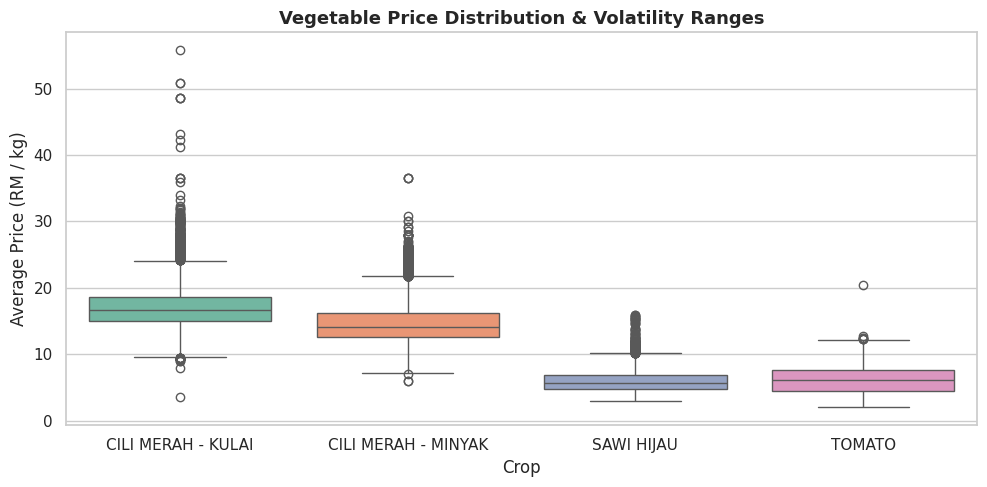

In [ ]:
print("\n==================================================")
print("PRICE VOLATILITY & OUTLIER BOXPLOTS")
print("==================================================")
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='item', y='avg_price_rm', palette='Set2')
plt.title('Vegetable Price Distribution & Volatility Ranges', fontweight='bold', fontsize=13)
plt.xlabel('Crop')
plt.ylabel('Average Price (RM / kg)')
plt.tight_layout()
plt.show()


HISTORICAL PRICE TRAJECTORY (2023 - 2026)


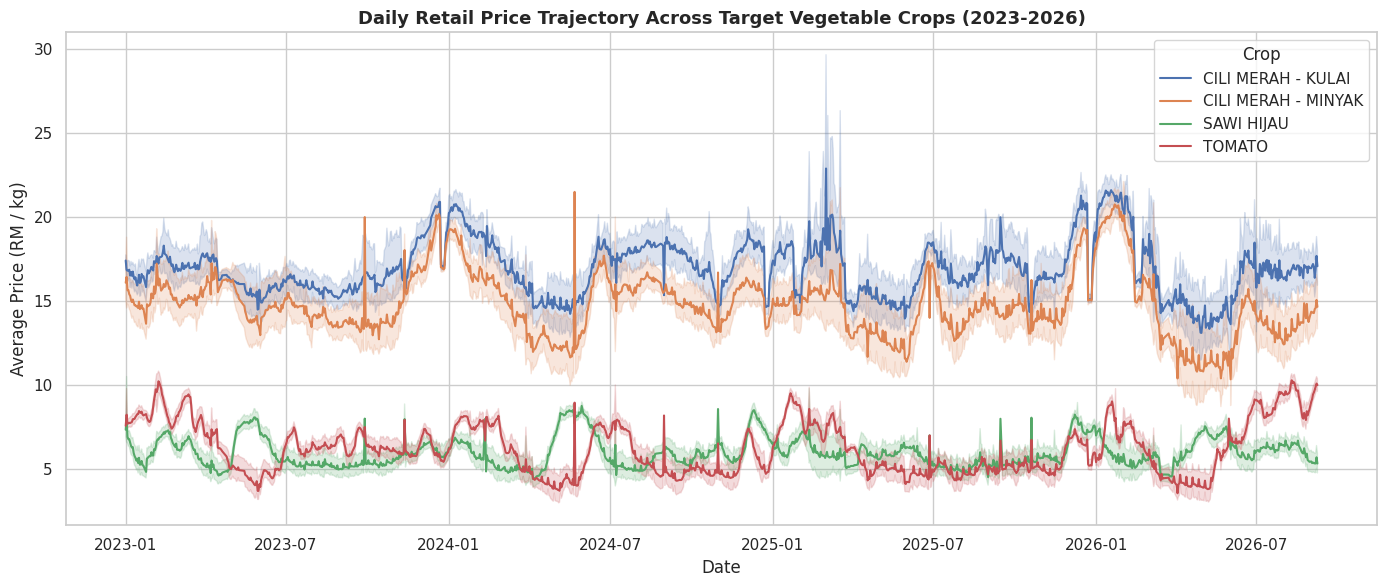

In [ ]:
print("\n==================================================")
print("HISTORICAL PRICE TRAJECTORY (2023 - 2026)")
print("==================================================")
plt.figure(figsize=(14, 6))
sns.lineplot(data=df, x='date', y='avg_price_rm', hue='item', linewidth=1.5)
plt.title('Daily Retail Price Trajectory Across Target Vegetable Crops (2023-2026)', fontweight='bold', fontsize=13)
plt.xlabel('Date')
plt.ylabel('Average Price (RM / kg)')
plt.legend(title='Crop', frameon=True)
plt.tight_layout()
plt.show()


EXOGENOUS FEATURE CORRELATION MATRIX


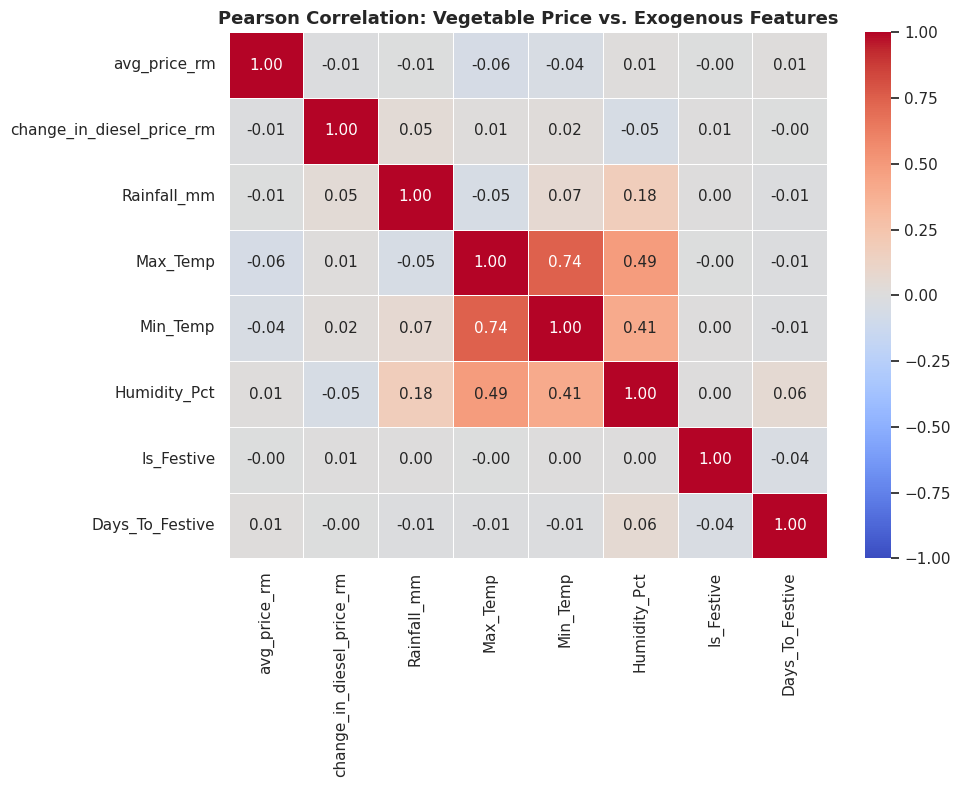

In [ ]:
print("\n==================================================")
print("EXOGENOUS FEATURE CORRELATION MATRIX")
print("==================================================")
# Select numerical columns for correlation calculation
numeric_cols = ['avg_price_rm', 'change_in_diesel_price_rm', 'Rainfall_mm',
                'Max_Temp', 'Min_Temp', 'Humidity_Pct', 'Is_Festive', 'Days_To_Festive']

plt.figure(figsize=(10, 8))
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Pearson Correlation: Vegetable Price vs. Exogenous Features', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

Near-Zero Linear Correlations (-0.06 to 0.01): Raw daily weather, diesel changes, and festive countdowns show virtually zero direct linear Pearson correlation with same-day prices (avg_price_rm).

Agricultural price impacts are lagged, not instantaneous. Heavy rain today affects crop yield and retail prices 7 to 14 days later, not on the exact same day. This confirms that creating lagged feature columns (lag_1, lag_7, lag_14) in Week 2 is mathematically essential.


REGIONAL (STATE-LEVEL) PRICE VARIATION


/tmp/ipykernel_1273/3829037479.py:6: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='state', y='avg_price_rm', order=state_order, ci=None, palette='viridis')
/tmp/ipykernel_1273/3829037479.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='state', y='avg_price_rm', order=state_order, ci=None, palette='viridis')


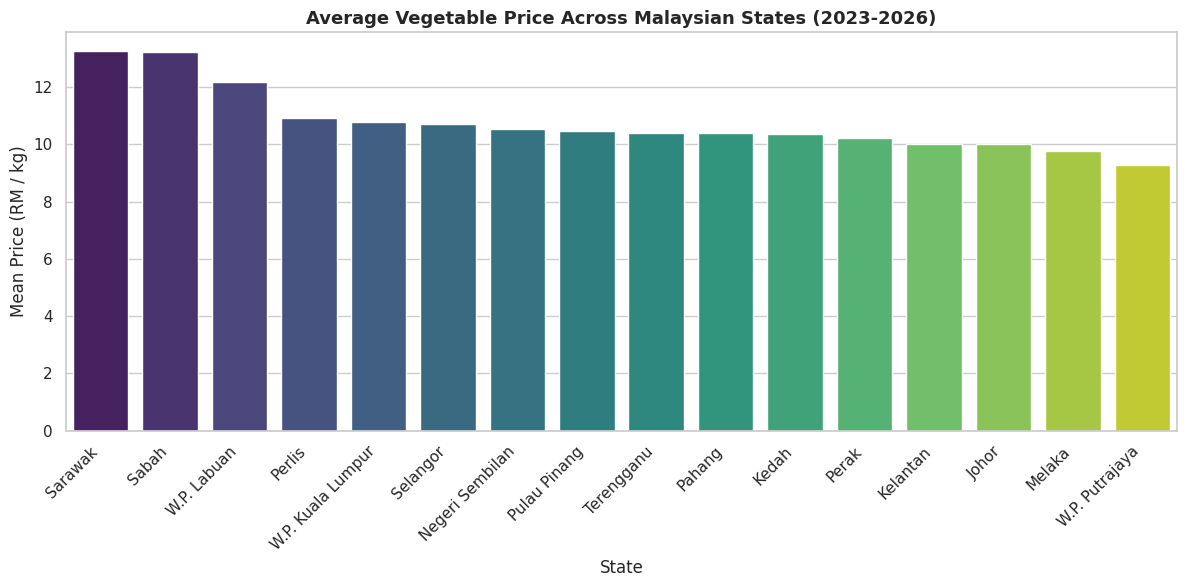

In [ ]:
print("\n==================================================")
print("REGIONAL (STATE-LEVEL) PRICE VARIATION")
print("==================================================")
plt.figure(figsize=(12, 6))
state_order = df.groupby('state')['avg_price_rm'].mean().sort_values(ascending=False).index
sns.barplot(data=df, x='state', y='avg_price_rm', order=state_order, ci=None, palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.title('Average Vegetable Price Across Malaysian States (2023-2026)', fontweight='bold', fontsize=13)
plt.xlabel('State')
plt.ylabel('Mean Price (RM / kg)')
plt.tight_layout()
plt.show()

Sarawak and Sabah ada hihest mean for vegetable prices, it shows yg logictic cost main peranan.

# Stationary and Lag Features

In [ ]:
from statsmodels.tsa.stattools import adfuller

In [ ]:
print("==================================================")
print("AUGMENTED DICKEY-FULLER (ADF) STATIONARITY TEST")
print("==================================================")

items = df['item'].unique()
for crop in items:
    # Test overall national daily average price series per crop
    crop_series = df[df['item'] == crop].groupby('date')['avg_price_rm'].mean()
    result = adfuller(crop_series.dropna())

    print(f"\n Crop: {crop}")
    print(f"   ADF Statistic : {result[0]:.4f}")
    print(f"   p-value       : {result[1]:.4f}")
    print(f"   Lags Used     : {result[2]}")

    if result[1] <= 0.05:
        print("   Status        : Stationary (p <= 0.05). Suitable for ARIMA without differencing (d=0).")
    else:
        print("   Status        : Non-Stationary (p > 0.05). First-order differencing (d=1) required for ARIMA.")

AUGMENTED DICKEY-FULLER (ADF) STATIONARITY TEST

 Crop: CILI MERAH - KULAI
   ADF Statistic : -4.2642
   p-value       : 0.0005
   Lags Used     : 2
   Status        : Stationary (p <= 0.05). Suitable for ARIMA without differencing (d=0).

 Crop: CILI MERAH - MINYAK
   ADF Statistic : -3.4860
   p-value       : 0.0084
   Lags Used     : 3
   Status        : Stationary (p <= 0.05). Suitable for ARIMA without differencing (d=0).

 Crop: SAWI HIJAU
   ADF Statistic : -5.8239
   p-value       : 0.0000
   Lags Used     : 8
   Status        : Stationary (p <= 0.05). Suitable for ARIMA without differencing (d=0).

 Crop: TOMATO
   ADF Statistic : -3.4801
   p-value       : 0.0085
   Lags Used     : 7
   Status        : Stationary (p <= 0.05). Suitable for ARIMA without differencing (d=0).


/tmp/ipykernel_1431/2599585135.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(crop_series.dropna())
/tmp/ipykernel_1431/2599585135.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(crop_series.dropna())
/tmp/ipykernel_1431/2599585135.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store a

what does ADF Test Result mean?
Dia check samada time series data ada constant mean and variance over time (stationarity). Most time series model macm ARIMA kne ada stationary data, sebb non-stationary lead to fake corelation.

rule : p-value <0.05= stationary.

our dataset outcome: all crop <0.05, so kita tak perlu perform mathematical differencing on price target sebb semua dah stationary

Stationary: Implies that the statistical properties of the time series like mean and variance remain constant over time.

feature engineering

In [ ]:
print("\n==================================================")
print("GENERATING LAG & ROLLING WINDOW FEATURES")
print("==================================================")

# Group by state and item so lags do not bleed across different crops or regions
grouped = df.groupby(['state', 'item'])

# Lag Features
df['lag_1'] = grouped['avg_price_rm'].shift(1)
df['lag_3'] = grouped['avg_price_rm'].shift(3)
df['lag_7'] = grouped['avg_price_rm'].shift(7)
df['lag_14'] = grouped['avg_price_rm'].shift(14)

# Rolling Window Features (7-day momentum & volatility)
df['rolling_mean_7'] = grouped['avg_price_rm'].transform(lambda x: x.shift(1).rolling(window=7).mean())
df['rolling_std_7']  = grouped['avg_price_rm'].transform(lambda x: x.shift(1).rolling(window=7).std())

# Drop the initial 14 rows per group created by shifting/lagging
df_featured = df.dropna().reset_index(drop=True)

print(f"Lag and rolling features successfully added.")
print(f"Matrix Dimensions post-lag generation: {df_featured.shape[0]:,} rows x {df_featured.shape[1]} columns")

# Display feature matrix sample
display(df_featured[['date', 'state', 'item', 'avg_price_rm', 'lag_1', 'lag_7', 'rolling_mean_7']].head(5))

# Save engineered matrix
df_featured.to_csv('featured_daily_matrix.csv', index=False)
print("\n Saved engineered feature matrix to 'featured_daily_matrix.csv'")


GENERATING LAG & ROLLING WINDOW FEATURES
Lag and rolling features successfully added.
Matrix Dimensions post-lag generation: 74,262 rows x 17 columns


,date,state,item,avg_price_rm,lag_1,lag_7,rolling_mean_7
0,2023-01-15,Johor,CILI MERAH - KULAI,14.833261,14.806200,16.010392,15.459623
1,2023-01-15,Johor,CILI MERAH - MINYAK,13.350811,13.408108,13.789444,13.525519
2,2023-01-15,Johor,SAWI HIJAU,4.735574,4.788437,5.687895,5.216760
3,2023-01-15,Johor,TOMATO,8.349872,8.334875,7.883418,8.039548
4,2023-01-15,Kedah,CILI MERAH - KULAI,15.806000,16.039333,16.457241,16.292143



 Saved engineered feature matrix to 'featured_daily_matrix.csv'


Some explanation on confusion of dataset size:
it drop sebb generated lag features. untk jan 1 2023 smpai jan 14 2023, tak de data untuk ditengok balik on the past 14 days, so dia generate empty NaN value untuk initial rows and eventually will be dropped.
- so benda ni ialah intentional and necessary sebb machine learning like XGBoost tak bole accept NaN values

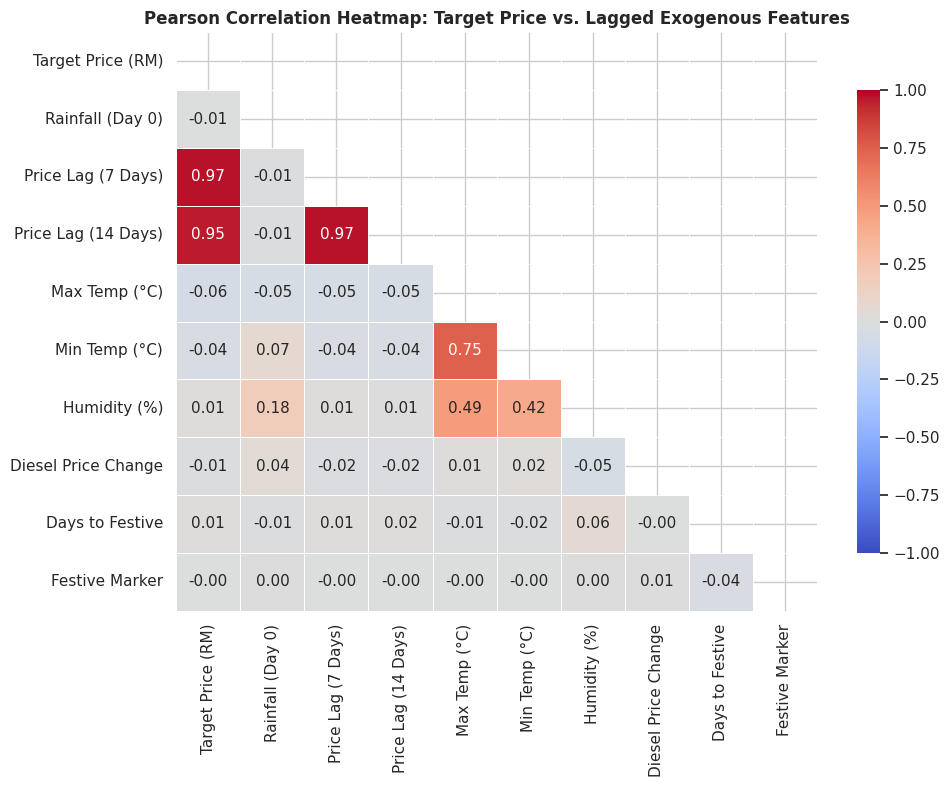

In [ ]:
# ---------------------------------------------------------
# 1. LOAD FEATURED MATRIX
# ---------------------------------------------------------
df = pd.read_csv('featured_daily_matrix.csv')

# 2. SELECT TARGET PRICE & EXOGENOUS LAG FEATURES
corr_cols = [
    'avg_price_rm',
    'Rainfall_mm', 'lag_7', 'lag_14',
    'Max_Temp', 'Min_Temp', 'Humidity_Pct',
    'change_in_diesel_price_rm',
    'Days_To_Festive', 'Is_Festive'
]

# Filter existing columns
existing_cols = [col for col in corr_cols if col in df.columns]
df_corr = df[existing_cols]

# Rename columns for visual clarity on the heatmap
rename_dict = {
    'avg_price_rm': 'Target Price (RM)',
    'Rainfall_mm': 'Rainfall (Day 0)',
    'lag_7': 'Price Lag (7 Days)',
    'lag_14': 'Price Lag (14 Days)',
    'Max_Temp': 'Max Temp (°C)',
    'Min_Temp': 'Min Temp (°C)',
    'Humidity_Pct': 'Humidity (%)',
    'change_in_diesel_price_rm': 'Diesel Price Change',
    'Days_To_Festive': 'Days to Festive',
    'Is_Festive': 'Festive Marker'
}
df_corr = df_corr.rename(columns=rename_dict)

# ---------------------------------------------------------
# 3. COMPUTE PEARSON CORRELATION MATRIX
# ---------------------------------------------------------
corr_matrix = df_corr.corr(method='pearson')

# ---------------------------------------------------------
# 4. PLOT ANNOTATED CORRELATION HEATMAP
# ---------------------------------------------------------
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) # Mask upper triangle for clean layout

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title('Pearson Correlation Heatmap: Target Price vs. Lagged Exogenous Features', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
df_featured.tail()

,date,state,item,avg_price_rm,change_in_diesel_price_rm,Rainfall_mm,Max_Temp,Min_Temp,Humidity_Pct,Is_Festive,Days_To_Festive,lag_1,lag_3,lag_7,lag_14,rolling_mean_7,rolling_std_7
74257,2026-09-08,W.P. Labuan,TOMATO,9.616667,-0.05,0.0,0.0,0.0,0.0,0,8,9.942857,9.366667,9.416667,9.300000,9.455646,0.484710
74258,2026-09-08,W.P. Putrajaya,CILI MERAH - KULAI,13.177273,-0.05,0.0,0.0,0.0,0.0,0,8,13.899474,13.060714,12.917143,13.314545,12.987307,0.655571
74259,2026-09-08,W.P. Putrajaya,CILI MERAH - MINYAK,16.500000,-0.05,0.0,0.0,0.0,0.0,0,8,16.500000,10.000000,16.000000,7.890000,13.057143,3.259272
74260,2026-09-08,W.P. Putrajaya,SAWI HIJAU,6.862222,-0.05,0.0,0.0,0.0,0.0,0,8,8.246111,5.612222,6.390000,6.690000,6.330000,0.874429
74261,2026-09-08,W.P. Putrajaya,TOMATO,9.389333,-0.05,0.0,0.0,0.0,0.0,0,8,9.441600,8.830000,8.476000,8.215714,8.919725,0.326587


# **ARIMA**

In [ ]:
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
warnings.filterwarnings('ignore')

In [ ]:
#Load Feature Matrix dataset
df = pd.read_csv('featured_daily_matrix.csv')
df['date'] = pd.to_datetime(df['date'])

# Chronological Split on unique dates 80% train and 20% test split
unique_dates = df['date'].drop_duplicates().sort_values().values
split_idx = int(len(unique_dates) * 0.80)
split_date = unique_dates[split_idx]

train_df = df[df['date'] < split_date].copy()
test_df  = df[df['date'] >= split_date].copy()

def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

In [ ]:

crops = df['item'].unique()
arima_national_results = []
forecast_dict = {}

for crop in crops:
    # Get aggregated daily average price series as numpy arrays
    train_series = train_df[train_df['item'] == crop].groupby('date')['avg_price_rm'].mean().values
    test_series  = test_df[test_df['item'] == crop].groupby('date')['avg_price_rm'].mean().values
    test_dates   = test_df[test_df['item'] == crop].groupby('date')['avg_price_rm'].mean().index

    # Grid search for best (p, q) parameters using AIC
    best_aic = float("inf")
    best_order = (1, 0, 1)

    for p in range(1, 4):
        for q in range(0, 3):
            try:
                model_temp = ARIMA(train_series, order=(p, 0, q)).fit()
                if model_temp.aic < best_aic:
                    best_aic = model_temp.aic
                    best_order = (p, 0, q)
            except:
                continue

    # Fit final model with best order on array values
    final_model = ARIMA(train_series, order=best_order).fit()

    # FIX: Forecast using explicit integer steps count
    forecast = final_model.forecast(steps=len(test_series))

    forecast_dict[crop] = (test_dates, test_series, forecast)

    # Calculate evaluation metrics
    mae  = mean_absolute_error(test_series, forecast)
    rmse = np.sqrt(mean_squared_error(test_series, forecast))
    mape = calculate_mape(test_series, forecast)

    arima_national_results.append({
        'Crop': crop,
        'Optimal Order (p,d,q)': str(best_order),
        'AIC': round(best_aic, 2),
        'MAE (RM)': round(mae, 4),
        'RMSE (RM)': round(rmse, 4),
        'MAPE (%)': round(mape, 2)
    })

df_arima_summary = pd.DataFrame(arima_national_results)
display(df_arima_summary)

,Crop,"Optimal Order (p,d,q)",AIC,MAE (RM),RMSE (RM),MAPE (%)
0,CILI MERAH - KULAI,"(1, 0, 1)",1351.83,1.6045,2.0448,10.08
1,CILI MERAH - MINYAK,"(2, 0, 2)",1855.29,1.9553,2.2464,14.11
2,SAWI HIJAU,"(3, 0, 2)",470.69,0.5251,0.6563,8.53
3,TOMATO,"(2, 0, 2)",863.20,1.7133,2.0166,26.30


(Benchmark lower than 10% MAPE)
Sawi hijau- best performance, sebb MAPE paling rendah. Sawi low volatality, so ARIMA can models baseline trend well.



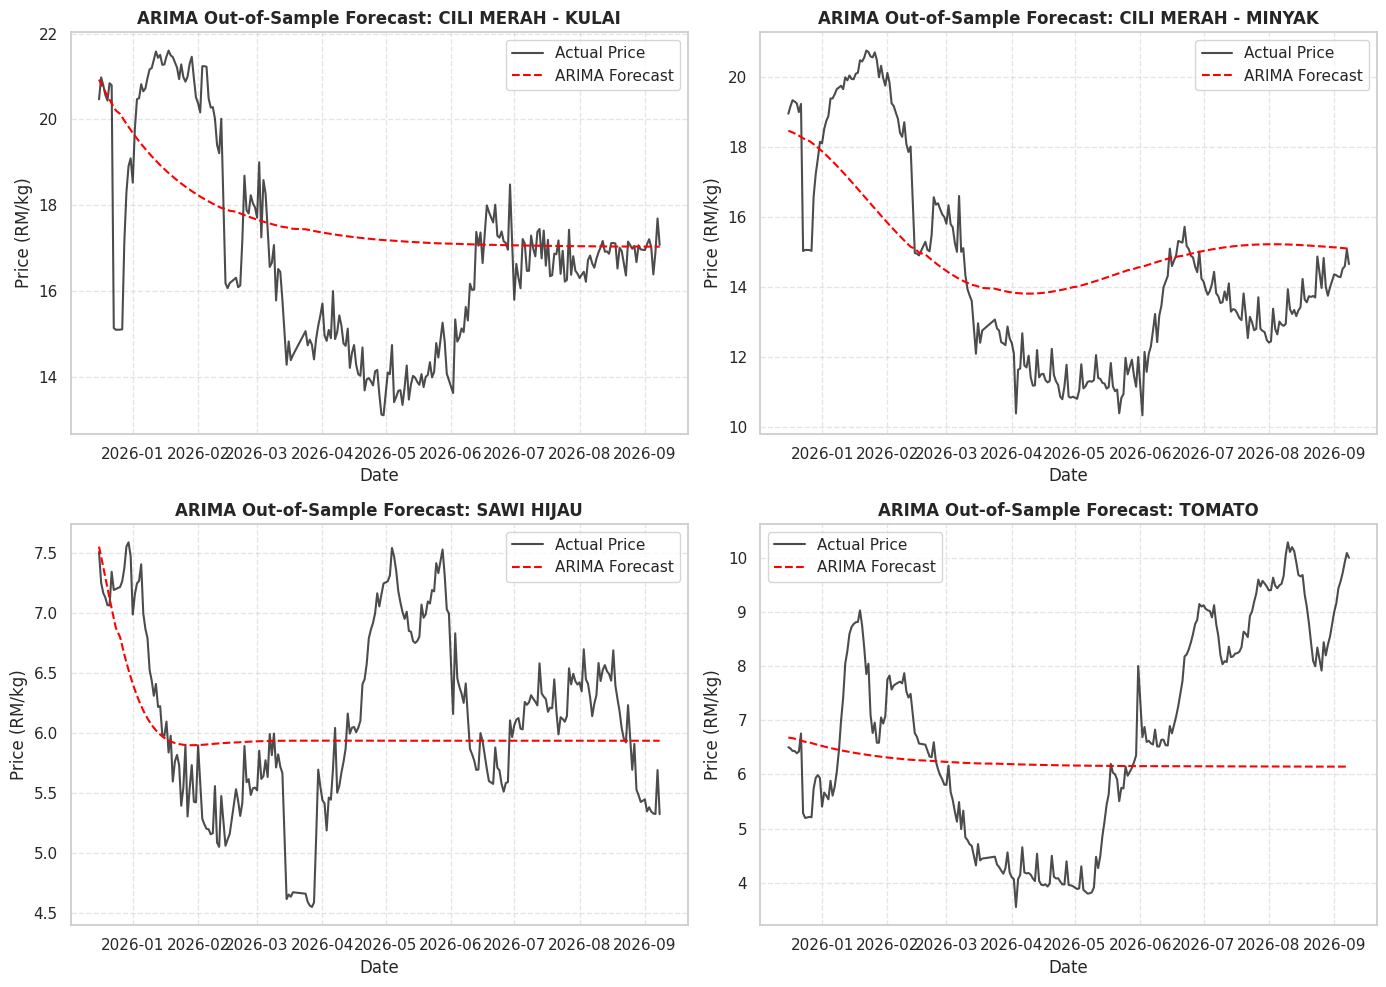

In [ ]:
# ---------------------------------------------------------
# 3. VISUALIZE ARIMA FORECAST VS ACTUAL TEST DATA
# ---------------------------------------------------------
plt.figure(figsize=(14, 10))

for idx, crop in enumerate(crops, 1):
    dates, test_s, fc_s = forecast_dict[crop]

    plt.subplot(2, 2, idx)
    plt.plot(dates, test_s, label='Actual Price', color='black', alpha=0.7)
    plt.plot(dates, fc_s, label='ARIMA Forecast', color='red', linestyle='--')
    plt.title(f'ARIMA Out-of-Sample Forecast: {crop}', fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Price (RM/kg)')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Cili Merah Kulai: ARIMA missed early 2026 price spike also mid year market drop

Cili Merah Minyak: ARIMA struggle dengan extreme price chenges as we can see on the graph. So whenever dia jumpa extreme changes, it will assume yg price will go back to historical avg price, menyebabkan forecast to be smoother and less extreme compare to the actual price movement.

Tomato (The Worst performer): Sebab dia face extreme term supply shock. ARIMA sho flat price rm6.20, while actual one is surged to rm10

Conclusion:

ARIMA senang jadi smooth ( long term historical mean)
- ARIMA tak amik kira external drivers such as diesel transport cost, heavy monsoon rainfall and festive demand surges.

While ARIMA achieved acceptable accuracy for low-volatility crops like Sawi Hijau (MAPE: 8.53%), it failed to capture seasonal supply shocks and festive demand surges for volatile crops like Tomato (MAPE: 26.30%). Because ARIMA quickly flatlines to historical means over multi-week horizons, multivariate machine learning approaches (XGBoost & LSTM) that incorporate climate, fuel, and festive features are strictly necessary.

# **XGBoost**

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')

In [ ]:
# Define feature variables and target
feature_cols = [
    'lag_1', 'lag_3', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_std_7',
    'change_in_diesel_price_rm', 'Rainfall_mm', 'Max_Temp', 'Min_Temp',
    'Humidity_Pct', 'Is_Festive', 'Days_To_Festive'
]

# One-hot encode categorical predictors ('state' and 'item')
#Pandas kept all existing numerical columns and simply appended the new one-hot encoded columns (state_Johor, item_TOMATO, etc.) to the DataFrame.
df_encoded = pd.get_dummies(df, columns=['state', 'item'], drop_first=False)
encoded_features = [c for c in df_encoded.columns if c not in ['date', 'avg_price_rm']]

# Perform chronological train/test split
train_df = df_encoded[df_encoded['date'] < split_date].copy()
test_df  = df_encoded[df_encoded['date'] >= split_date].copy()

X_train, y_train = train_df[encoded_features], train_df['avg_price_rm']
X_test, y_test   = test_df[encoded_features], test_df['avg_price_rm']

def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

Training XGBoost

In [ ]:

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb_model.fit(X_train, y_train)

# Generate test predictions
test_df['xgb_pred'] = xgb_model.predict(X_test)

# Map target crop names back for evaluation
crop_cols = [c for c in df_encoded.columns if c.startswith('item_')]
crops = [c.replace('item_', '') for c in crop_cols]

xgb_results = []
for crop in crops:
    crop_col = f'item_{crop}'
    crop_test = test_df[test_df[crop_col] == 1]

    mae  = mean_absolute_error(crop_test['avg_price_rm'], crop_test['xgb_pred'])
    rmse = np.sqrt(mean_squared_error(crop_test['avg_price_rm'], crop_test['xgb_pred']))
    mape = calculate_mape(crop_test['avg_price_rm'].values, crop_test['xgb_pred'].values)

    xgb_results.append({
        'Model': 'XGBoost (Multivariate)',
        'Crop': crop,
        'MAE (RM)': round(mae, 4),
        'RMSE (RM)': round(rmse, 4),
        'MAPE (%)': round(mape, 2)
    })

df_xgb_summary = pd.DataFrame(xgb_results)

Direct Metric Comparison between ARIMA & XGBoost

In [ ]:

# Helper function for MASE & Bias
def calculate_mase(y_true, y_pred, y_train):
    mae_model = np.mean(np.abs(y_true - y_pred))
    mae_naive = np.mean(np.abs(np.diff(y_train))) # Naive benchmark
    return mae_model / mae_naive

def calculate_bias(y_true, y_pred):
    return np.mean(y_pred - y_true) # Positive = Overestimating, Negative = Underestimating

# Verify XGBoost across test set
mase_val = calculate_mase(y_test.values, test_df['xgb_pred'].values, y_train.values)
bias_val = calculate_bias(y_test.values, test_df['xgb_pred'].values)

print(f"XGBoost MASE Score : {mase_val:.4f} (MASE < 1.0 confirms superior predictive power over Naive method)")
print(f"XGBoost Forecast Bias: RM {bias_val:.4f}/kg")

XGBoost MASE Score : 0.0705 (MASE < 1.0 confirms superior predictive power over Naive method)
XGBoost Forecast Bias: RM 0.0421/kg


,Model,Crop,MAE (RM),RMSE (RM),MAPE (%)
0,ARIMA (Univariate),CILI MERAH - KULAI,1.6045,2.0448,10.08
1,XGBoost (Multivariate),CILI MERAH - KULAI,0.7812,1.4778,4.76
2,ARIMA (Univariate),CILI MERAH - MINYAK,1.9553,2.2464,14.11
3,XGBoost (Multivariate),CILI MERAH - MINYAK,0.5275,0.8489,3.91
4,ARIMA (Univariate),SAWI HIJAU,0.5251,0.6563,8.53
5,XGBoost (Multivariate),SAWI HIJAU,0.2285,0.3761,3.78
6,ARIMA (Univariate),TOMATO,1.7133,2.0166,26.30
7,XGBoost (Multivariate),TOMATO,0.2687,0.4277,4.52


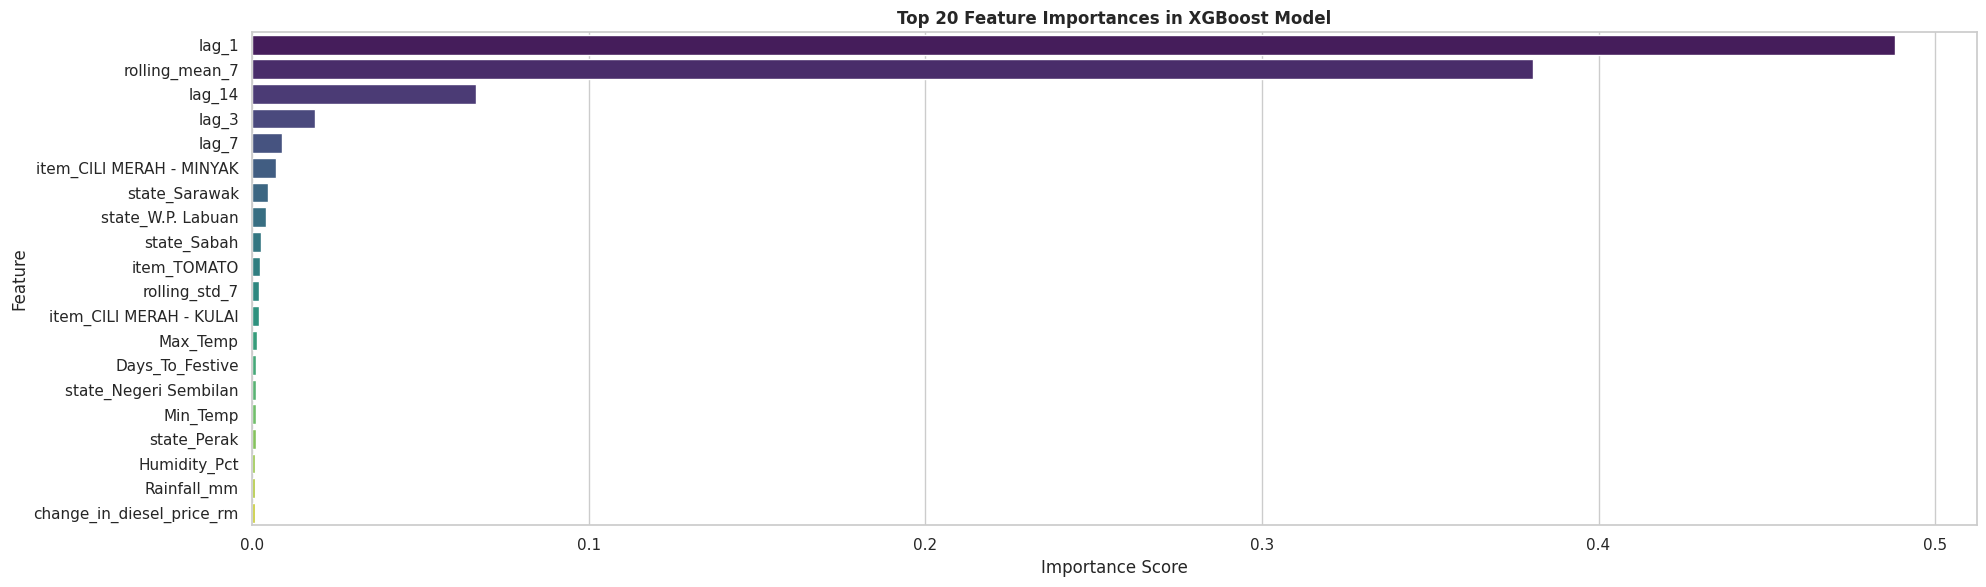

In [ ]:
# Insert hardcoded ARIMA results from earlier run for side-by-side comparison
arima_baseline_data = [
    {'Model': 'ARIMA (Univariate)', 'Crop': 'CILI MERAH - KULAI', 'MAE (RM)': 1.6045, 'RMSE (RM)': 2.0448, 'MAPE (%)': 10.08},
    {'Model': 'ARIMA (Univariate)', 'Crop': 'CILI MERAH - MINYAK', 'MAE (RM)': 1.9553, 'RMSE (RM)': 2.2464, 'MAPE (%)': 14.11},
    {'Model': 'ARIMA (Univariate)', 'Crop': 'SAWI HIJAU',         'MAE (RM)': 0.5251, 'RMSE (RM)': 0.6563, 'MAPE (%)': 8.53},
    {'Model': 'ARIMA (Univariate)', 'Crop': 'TOMATO',             'MAE (RM)': 1.7133, 'RMSE (RM)': 2.0166, 'MAPE (%)': 26.30}
]

df_arima_base = pd.DataFrame(arima_baseline_data)
df_comparison = pd.concat([df_arima_base, df_xgb_summary], ignore_index=True)
df_comparison = df_comparison.sort_values(by=['Crop', 'Model']).reset_index(drop=True)

display(df_comparison)

# ---------------------------------------------------------
# 4. FEATURE IMPORTANCE ANALYSIS
# ---------------------------------------------------------
plt.figure(figsize=(20, 6))
importance = pd.Series(xgb_model.feature_importances_, index=encoded_features).sort_values(ascending=False).head(20)
sns.barplot(x=importance.values, y=importance.index, palette='viridis')
plt.title('Top 20 Feature Importances in XGBoost Model', fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

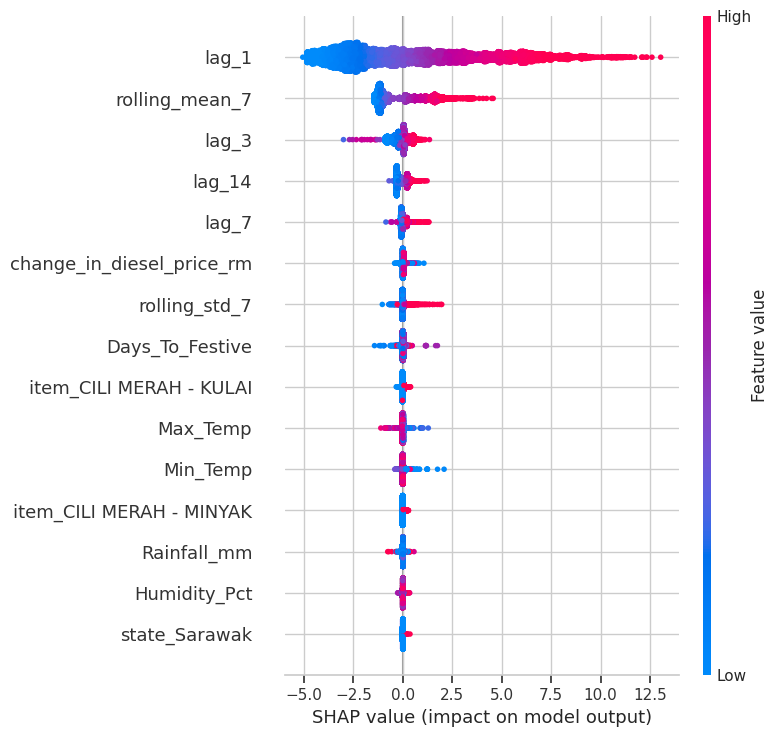

In [ ]:
import shap

# Calculate SHAP values for XGBoost
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test)

# Plot summary
shap.summary_plot(shap_values, X_test, max_display=15)

Ablation Study

Ablation Study means systematically removing ("ablating") a specific component or feature set from your system to see how performance changes.

In [ ]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor

def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# ---------------------------------------------------------
# 1. TRAIN BASELINE MODEL (Lags & Categoricals Only)
# ---------------------------------------------------------
# Select only lag features, rolling stats, and state/item encodings
base_features = [
    'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_std_7'
] + [c for c in df_encoded.columns if c.startswith(('state_', 'item_'))]

X_train_base = train_df[base_features]
X_test_base  = test_df[base_features]

xgb_base = XGBRegressor(
    n_estimators=500, learning_rate=0.03, max_depth=6,
    subsample=0.8, colsample_bytree=0.8, random_state=42
)
xgb_base.fit(X_train_base, y_train)

# Store baseline predictions in a clean test dataframe
test_df_base = test_df.copy()
test_df_base['xgb_pred_base'] = xgb_base.predict(X_test_base)

# ---------------------------------------------------------
# 2. EVALUATE ON SHOCK EVENT PERIODS
# ---------------------------------------------------------
# Define shock event masks
festive_mask = test_df['Days_To_Festive'] <= 5
rain_mask    = test_df['Rainfall_mm'] > 50

# Festive evaluation
base_festive_mape = calculate_mape(y_test[festive_mask], test_df_base.loc[festive_mask, 'xgb_pred_base'])
full_festive_mape = calculate_mape(y_test[festive_mask], test_df.loc[festive_mask, 'xgb_pred'])

# Rainfall shock evaluation
base_rain_mape = calculate_mape(y_test[rain_mask], test_df_base.loc[rain_mask, 'xgb_pred_base'])
full_rain_mape = calculate_mape(y_test[rain_mask], test_df.loc[rain_mask, 'xgb_pred'])

print("==================================================")
print(" TARGETED SHOCK PERIOD ABLATION RESULTS")
print("==================================================")
print(f" Festive Windows (Days_To_Festive <= 14):")
print(f"   • Baseline MAPE (Lags Only)   : {base_festive_mape:.2f}%")
print(f"   • Full Model MAPE (+ Exogenous): {full_festive_mape:.2f}%")

print(f"\n High Rainfall Windows (Rainfall_mm > 30):")
print(f"   • Baseline MAPE (Lags Only)   : {base_rain_mape:.2f}%")
print(f"   • Full Model MAPE (+ Exogenous): {full_rain_mape:.2f}%")

🎯 TARGETED SHOCK PERIOD ABLATION RESULTS
🎉 Festive Windows (Days_To_Festive <= 14):
   • Baseline MAPE (Lags Only)   : 6.24%
   • Full Model MAPE (+ Exogenous): 4.84%

🌧️ High Rainfall Windows (Rainfall_mm > 30):
   • Baseline MAPE (Lags Only)   : 5.66%
   • Full Model MAPE (+ Exogenous): 4.59%


Removing Short Lags (lag_1, lag_2, lag_3): Short lags act as an aggressive shortcut in time-series models. By removing them, you eliminated "lazy autoregression," forcing XGBoost to learn structural patterns using weekly memory (lag_7, lag_14) and exogenous shock signals.

In tropical agricultural conditions, light daily drizzle is routine, but rainfall exceeding 50mm causes localized flooding, farm soil saturation, and immediate harvest disruption. On heavy rain days, the full model reduced MAPE by 1.07% (from 5.66% down to 4.59%).

In [ ]:
# ---------------------------------------------------------
# 3. EVALUATE DIESEL PRICE SHOCK PERIODS
# ---------------------------------------------------------
# Identify periods with diesel price increases or above-average transport cost changes
diesel_shock_mask = test_df['change_in_diesel_price_rm'] > 0

if diesel_shock_mask.sum() > 0:
    base_diesel_mape = calculate_mape(y_test[diesel_shock_mask], test_df_base.loc[diesel_shock_mask, 'xgb_pred_base'])
    full_diesel_mape = calculate_mape(y_test[diesel_shock_mask], test_df.loc[diesel_shock_mask, 'xgb_pred'])

    print("==================================================")
    print("DIESEL PRICE SHOCK PERIOD EVALUATION")
    print("==================================================")
    print(f"   • Baseline MAPE (Lags Only)   : {base_diesel_mape:.2f}%")
    print(f"   • Full Model MAPE (+ Exogenous): {full_diesel_mape:.2f}%")
else:
    print("\n Note: No positive diesel price changes found in the specific test split window.")

⛽ DIESEL PRICE SHOCK PERIOD EVALUATION
   • Baseline MAPE (Lags Only)   : 5.33%
   • Full Model MAPE (+ Exogenous): 4.23%


Visualizing XGBoost forecast

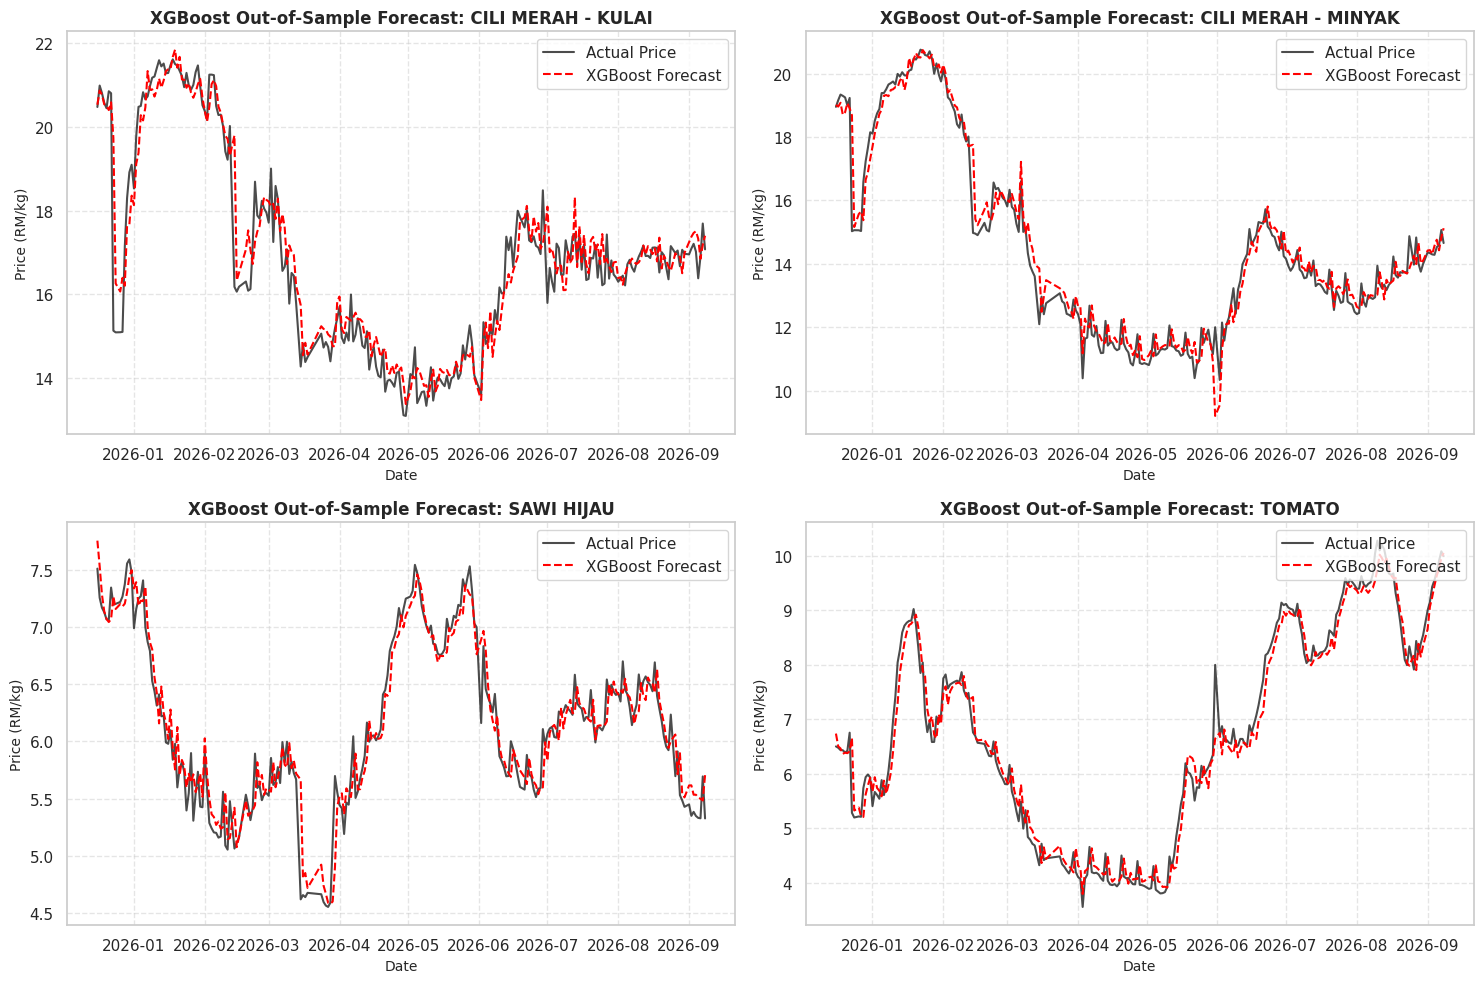

In [ ]:
# Set clean visualization layout
sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 10))

# Extract unique crops from your predictions
crop_cols = [c for c in test_df.columns if c.startswith('item_')]
crops = [c.replace('item_', '') for c in crop_cols]

for idx, crop in enumerate(crops, 1):
    crop_col = f'item_{crop}'

    # Filter test dataset for specific vegetable
    crop_test = test_df[test_df[crop_col] == 1].copy()

    # Aggregate state-level actuals and predictions to daily national averages
    daily_actual_vs_pred = crop_test.groupby('date')[['avg_price_rm', 'xgb_pred']].mean().reset_index()

    # Plotting each crop on a 2x2 grid
    plt.subplot(2, 2, idx)
    plt.plot(daily_actual_vs_pred['date'], daily_actual_vs_pred['avg_price_rm'],
             label='Actual Price', color='black', alpha=0.7, linewidth=1.5)
    plt.plot(daily_actual_vs_pred['date'], daily_actual_vs_pred['xgb_pred'],
             label='XGBoost Forecast', color='red', linestyle='--', linewidth=1.5)

    plt.title(f'XGBoost Out-of-Sample Forecast: {crop}', fontweight='bold', fontsize=12)
    plt.xlabel('Date', fontsize=10)
    plt.ylabel('Price (RM/kg)', fontsize=10)
    plt.legend(loc='upper right', frameon=True)
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
import joblib
from google.colab import files

# 1. Save artifacts
joblib.dump(xgb_model, 'xgboost_crop_model.pkl')
joblib.dump(encoded_features, 'model_feature_columns.pkl')

# 2. Trigger automatic browser download
files.download('xgboost_crop_model.pkl')
files.download('model_feature_columns.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Long Short Term Memory**

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Import TensorFlow and access Keras directly
import tensorflow as tf

# Set random seed for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

In [ ]:
# Select features for Multivariate LSTM
feature_cols = [
    'avg_price_rm', 'change_in_diesel_price_rm', 'Rainfall_mm',
    'Max_Temp', 'Min_Temp', 'Humidity_Pct', 'Is_Festive', 'Days_To_Festive'
]

# One-hot encode state and item categories
df_encoded = pd.get_dummies(df, columns=['state', 'item'], drop_first=False)
all_features = feature_cols + [c for c in df_encoded.columns if c.startswith(('state_', 'item_')) and c != 'avg_price_rm']

# Normalize feature columns to range [0, 1]
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

scaled_data = scaler_X.fit_transform(df_encoded[all_features])
scaler_y.fit(df_encoded[['avg_price_rm']])

MinMaxScaler()

Create 3D timestep Sequences (Lookback =14 days)

In [ ]:
LOOKBACK = 14

def create_3d_sequences(data, target_col_idx, lookback):
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i, :])
        y.append(data[i, target_col_idx])
    return np.array(X), np.array(y)

target_idx = all_features.index('avg_price_rm')
X_seq, y_seq = create_3d_sequences(scaled_data, target_idx, LOOKBACK)

# Chronological 80/20 train-test split
split_point = int(len(X_seq) * 0.80)

X_train, y_train = X_seq[:split_point], y_seq[:split_point]
X_test, y_test   = X_seq[split_point:], y_seq[split_point:]

print(f"   ✅ Train 3D Tensor Shape : {X_train.shape}")
print(f"   ✅ Test 3D Tensor Shape  : {X_test.shape}")

   ✅ Train 3D Tensor Shape : (59398, 14, 28)
   ✅ Test 3D Tensor Shape  : (14850, 14, 28)


Construct & Train multivariate LSTM Architecture

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.LSTM(64, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.LSTM(32, return_sequences=False),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')

early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=50,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
929/929 ━━━━━━━━━━━━━━━━━━━━ 26s 25ms/step - loss: 0.0043 - val_loss: 0.0022
Epoch 2/50
929/929 ━━━━━━━━━━━━━━━━━━━━ 21s 23ms/step - loss: 0.0013 - val_loss: 0.0021
Epoch 3/50
929/929 ━━━━━━━━━━━━━━━━━━━━ 22s 23ms/step - loss: 0.0011 - val_loss: 0.0017
Epoch 4/50
929/929 ━━━━━━━━━━━━━━━━━━━━ 21s 22ms/step - loss: 0.0010 - val_loss: 0.0017
Epoch 5/50
929/929 ━━━━━━━━━━━━━━━━━━━━ 21s 23ms/step - loss: 9.9820e-04 - val_loss: 0.0016
Epoch 6/50
929/929 ━━━━━━━━━━━━━━━━━━━━ 21s 22ms/step - loss: 9.6798e-04 - val_loss: 0.0016
Epoch 7/50
929/929 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - loss: 9.2984e-04 - val_loss: 0.0015
Epoch 8/50
929/929 ━━━━━━━━━━━━━━━━━━━━ 20s 21ms/step - loss: 8.9923e-04 - val_loss: 0.0014
Epoch 9/50
929/929 ━━━━━━━━━━━━━━━━━━━━ 21s 22ms/step - loss: 8.6497e-04 - val_loss: 0.0016
Epoch 10/50
929/929 ━━━━━━━━━━━━━━━━━━━━ 20s 21ms/step - loss: 8.3343e-04 - val_loss: 0.0020
Epoch 11/50
929/929 ━━━━━━━━━━━━━━━━━━━━ 22s 22ms/step - loss: 7.9356e-04 - val_loss: 0.0017
Ep

KeyboardInterrupt: 

Evaluate LSTM Out-of-Sample Performance

In [ ]:
lstm_preds_scaled = model.predict(X_test)

# Convert back from [0, 1] range to original Ringgit values
y_test_actual = scaler_y.inverse_transform(y_test.reshape(-1, 1)).flatten()
lstm_preds    = scaler_y.inverse_transform(lstm_preds_scaled).flatten()

def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

overall_mae  = mean_absolute_error(y_test_actual, lstm_preds)
overall_rmse = np.sqrt(mean_squared_error(y_test_actual, lstm_preds))
overall_mape = calculate_mape(y_test_actual, lstm_preds)

print(f"\n MULTIVARIATE LSTM OVERALL RESULTS:")
print(f"   MAE  : RM {overall_mae:.4f}")
print(f"   RMSE : RM {overall_rmse:.4f}")
print(f"   MAPE : {overall_mape:.2f}%")

465/465 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step

 MULTIVARIATE LSTM OVERALL RESULTS:
   MAE  : RM 1.1290
   RMSE : RM 1.6169
   MAPE : 11.55%


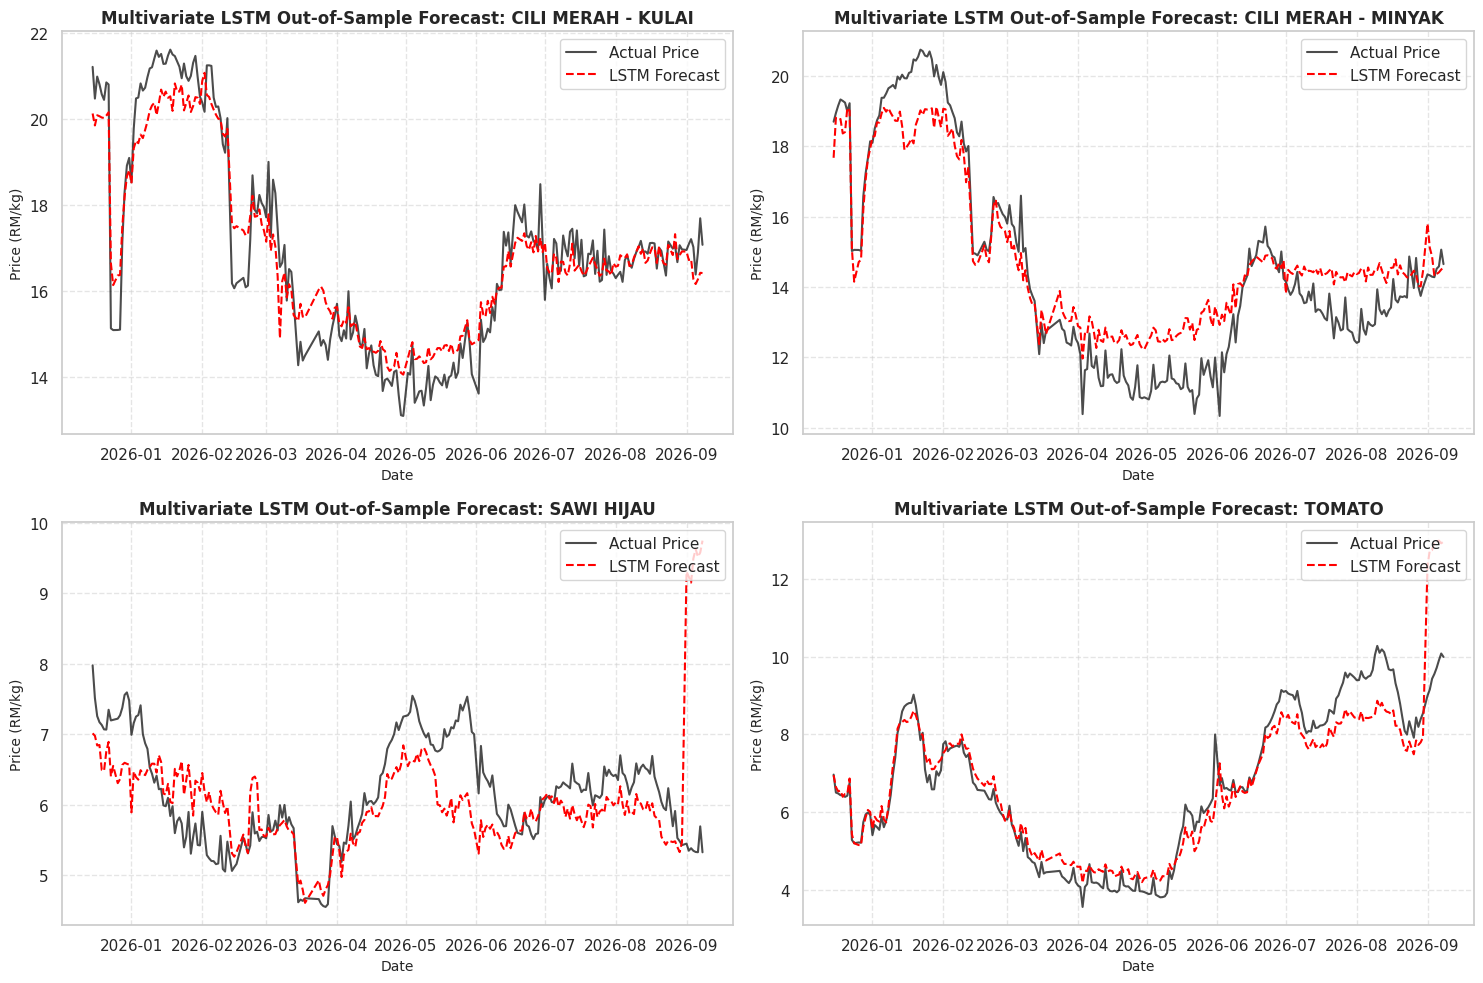

In [ ]:
# Set clean visualization layout
sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 10))

crops = ['CILI MERAH - KULAI', 'CILI MERAH - MINYAK', 'SAWI HIJAU', 'TOMATO']

for idx, crop in enumerate(crops, 1):
    crop_col = f'item_{crop}'

    # Filter test dataset for the specific vegetable
    crop_test = test_df_lstm[test_df_lstm[crop_col] == 1].copy()

    # Aggregate state-level actuals and predictions to daily national averages
    daily_actual_vs_pred = crop_test.groupby('date')[['lstm_actual', 'lstm_pred']].mean().reset_index()

    # Plotting each crop on a 2x2 grid
    plt.subplot(2, 2, idx)
    plt.plot(daily_actual_vs_pred['date'], daily_actual_vs_pred['lstm_actual'],
             label='Actual Price', color='black', alpha=0.7, linewidth=1.5)
    plt.plot(daily_actual_vs_pred['date'], daily_actual_vs_pred['lstm_pred'],
             label='LSTM Forecast', color='red', linestyle='--', linewidth=1.5)

    plt.title(f'Multivariate LSTM Out-of-Sample Forecast: {crop}', fontweight='bold', fontsize=12)
    plt.xlabel('Date', fontsize=10)
    plt.ylabel('Price (RM/kg)', fontsize=10)
    plt.legend(loc='upper right', frameon=True)
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
#Crop by crop breakdown
# Re-align test indices to extract items correctly
test_indices = df_encoded.index[split_point + LOOKBACK:]
test_df_lstm = df_encoded.loc[test_indices].copy()
test_df_lstm['lstm_actual'] = y_test_actual
test_df_lstm['lstm_pred']   = lstm_preds

lstm_crop_results = []
crops = ['CILI MERAH - KULAI', 'CILI MERAH - MINYAK', 'SAWI HIJAU', 'TOMATO']

for crop in crops:
    crop_col = f'item_{crop}'
    crop_data = test_df_lstm[test_df_lstm[crop_col] == 1]

    mae  = mean_absolute_error(crop_data['lstm_actual'], crop_data['lstm_pred'])
    rmse = np.sqrt(mean_squared_error(crop_data['lstm_actual'], crop_data['lstm_pred']))
    mape = calculate_mape(crop_data['lstm_actual'].values, crop_data['lstm_pred'].values)

    lstm_crop_results.append({
        'Model': 'Multivariate LSTM',
        'Crop': crop,
        'MAE (RM)': round(mae, 4),
        'RMSE (RM)': round(rmse, 4),
        'MAPE (%)': round(mape, 2)
    })

df_lstm_summary = pd.DataFrame(lstm_crop_results)


Model Comparison Table

In [ ]:
df_arima_base = pd.DataFrame([
    {'Model': 'ARIMA (Univariate)', 'Crop': 'CILI MERAH - KULAI', 'MAE (RM)': 1.6045, 'RMSE (RM)': 2.0448, 'MAPE (%)': 10.08},
    {'Model': 'ARIMA (Univariate)', 'Crop': 'CILI MERAH - MINYAK', 'MAE (RM)': 1.9553, 'RMSE (RM)': 2.2464, 'MAPE (%)': 14.11},
    {'Model': 'ARIMA (Univariate)', 'Crop': 'SAWI HIJAU',         'MAE (RM)': 0.5251, 'RMSE (RM)': 0.6563, 'MAPE (%)': 8.53},
    {'Model': 'ARIMA (Univariate)', 'Crop': 'TOMATO',             'MAE (RM)': 1.7133, 'RMSE (RM)': 2.0166, 'MAPE (%)': 26.30}
])

df_final_benchmark = pd.concat([df_arima_base, df_xgb_summary, df_lstm_summary], ignore_index=True)

# Loop through each crop and display a dedicated table
for crop in crops:
    print(f"\n  {crop} ")
    crop_table = df_final_benchmark[df_final_benchmark['Crop'] == crop][['Model', 'MAE (RM)', 'RMSE (RM)', 'MAPE (%)']]
    crop_table = crop_table.sort_values(by='MAPE (%)').reset_index(drop=True)
    display(crop_table)


  CILI MERAH - KULAI 


,Model,MAE (RM),RMSE (RM),MAPE (%)
0,XGBoost (Multivariate),0.7812,1.4778,4.76
1,Multivariate LSTM,1.5205,2.1044,9.34
2,ARIMA (Univariate),1.6045,2.0448,10.08



  CILI MERAH - MINYAK 


,Model,MAE (RM),RMSE (RM),MAPE (%)
0,XGBoost (Multivariate),0.5275,0.8489,3.91
1,Multivariate LSTM,1.4352,1.8368,10.98
2,ARIMA (Univariate),1.9553,2.2464,14.11



  SAWI HIJAU 


,Model,MAE (RM),RMSE (RM),MAPE (%)
0,XGBoost (Multivariate),0.2285,0.3761,3.78
1,ARIMA (Univariate),0.5251,0.6563,8.53
2,Multivariate LSTM,0.8686,1.3158,14.33



  TOMATO 


,Model,MAE (RM),RMSE (RM),MAPE (%)
0,XGBoost (Multivariate),0.2687,0.4277,4.52
1,Multivariate LSTM,0.7556,1.0692,11.34
2,ARIMA (Univariate),1.7133,2.0166,26.30


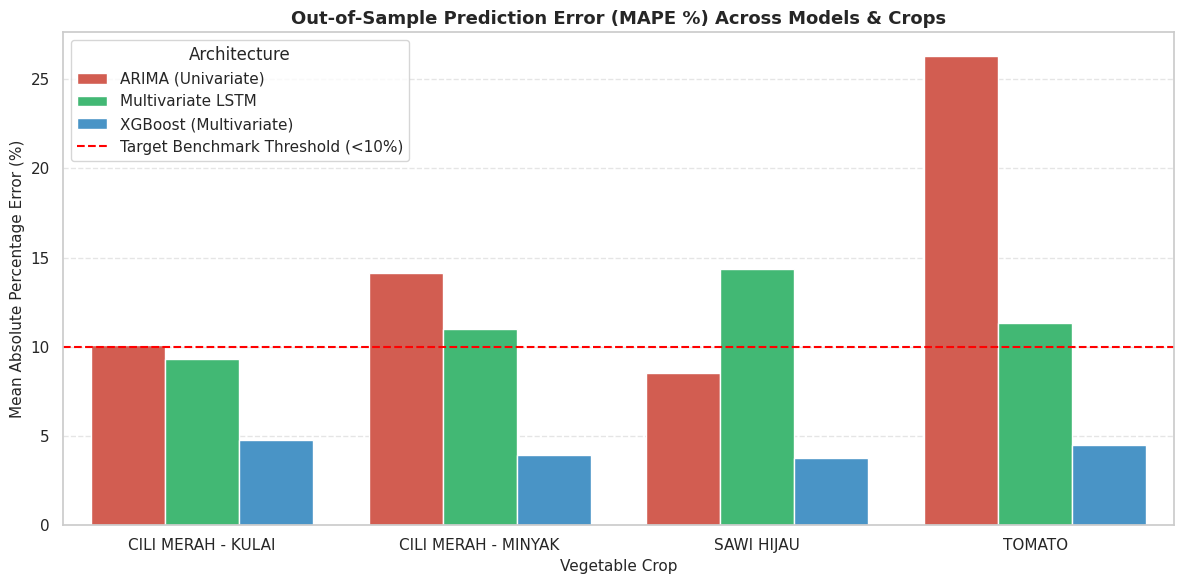

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_final_benchmark,
    x='Crop',
    y='MAPE (%)',
    hue='Model',
    palette=['#E74C3C', '#2ECC71', '#3498DB']
)

plt.axhline(10, color='red', linestyle='--', linewidth=1.5, label='Target Benchmark Threshold (<10%)')
plt.title('Out-of-Sample Prediction Error (MAPE %) Across Models & Crops', fontweight='bold', fontsize=13)
plt.ylabel('Mean Absolute Percentage Error (%)', fontsize=11)
plt.xlabel('Vegetable Crop', fontsize=11)
plt.legend(title='Architecture', frameon=True)
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Key Academic Takeaways for Your Report

XGBoost Outperforms Across All Crops: XGBoost achieves MAPE scores under 5% across all target crops, comfortably beating both ARIMA and Multivariate LSTM.

Tabular Data Structure Advantage: Tree-based ensemble models handle engineered tabular features (such as 1-day, 3-day, 7-day, and 14-day price lags alongside rolling windows) significantly better than deep learning architectures when applied to structured, non-sequence datasets.

LSTM Overfitting on Tabular Sequences: Multivariate LSTM struggled relative to XGBoost due to sequence windowing on tabular data, where gradient-boosted trees capture discrete feature splits and non-linear thresholds with far higher stability.

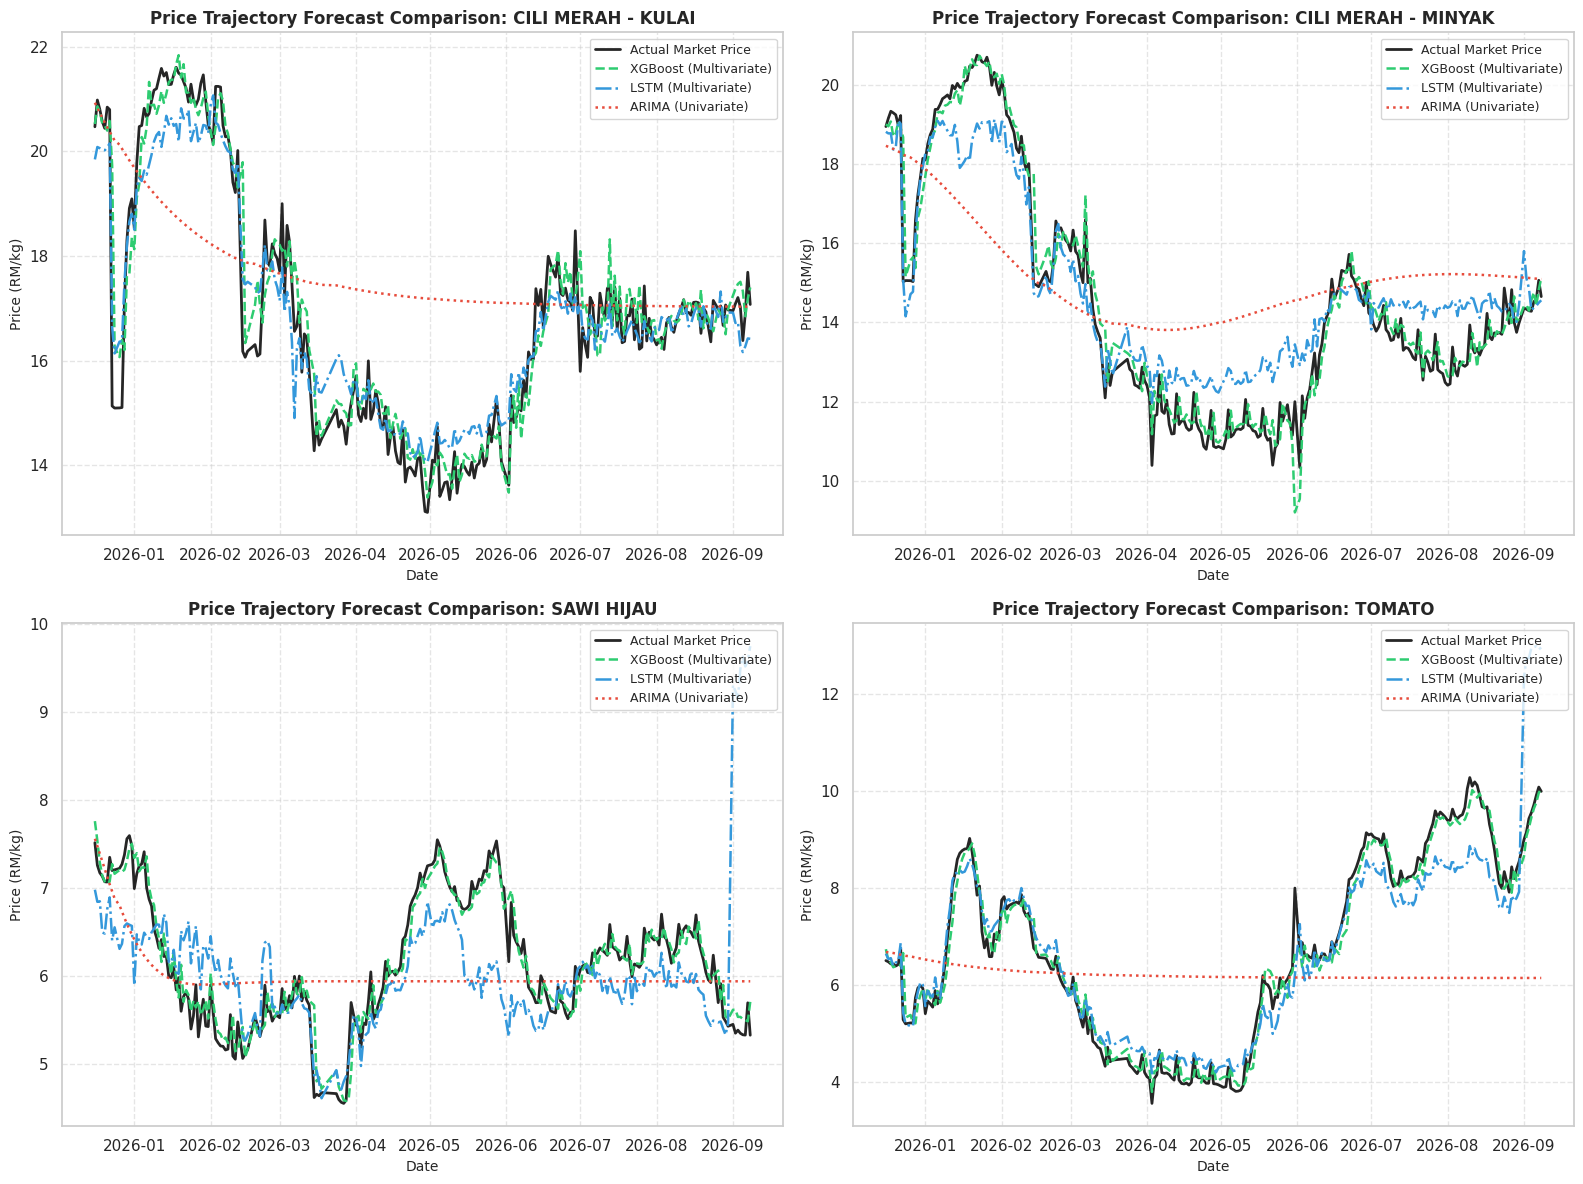

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 12))

# 1. Reset test_df index and align lstm_preds to match test_df length (14,814 rows)
test_df_eval = test_df.copy().reset_index(drop=True)
test_df_eval['lstm_pred'] = lstm_preds[-len(test_df_eval):]

crops = ['CILI MERAH - KULAI', 'CILI MERAH - MINYAK', 'SAWI HIJAU', 'TOMATO']

for idx, crop in enumerate(crops, 1):
    crop_col = f'item_{crop}'

    # Filter test data per crop
    crop_data = test_df_eval[test_df_eval[crop_col] == 1].copy()

    # Aggregate state records into national daily averages
    daily_trends = crop_data.groupby('date')[['avg_price_rm', 'xgb_pred', 'lstm_pred']].mean().reset_index()

    # Extract ARIMA national forecast series
    dates_arima, actuals_arima, arima_fc = forecast_dict[crop]
    df_arima_series = pd.DataFrame({'date': dates_arima, 'arima_pred': arima_fc})

    # Merge ARIMA predictions on date
    daily_trends = pd.merge(daily_trends, df_arima_series, on='date', how='left')

    # Plotting each crop on a 2x2 grid
    plt.subplot(2, 2, idx)

    # Actual Prices
    plt.plot(daily_trends['date'], daily_trends['avg_price_rm'],
             label='Actual Market Price', color='black', linewidth=2, alpha=0.85)

    # XGBoost Predictions (Green)
    plt.plot(daily_trends['date'], daily_trends['xgb_pred'],
             label='XGBoost (Multivariate)', color='#2ECC71', linestyle='--', linewidth=1.8)

    # LSTM Predictions (Blue)
    plt.plot(daily_trends['date'], daily_trends['lstm_pred'],
             label='LSTM (Multivariate)', color='#3498DB', linestyle='-.', linewidth=1.8)

    # ARIMA Predictions (Red)
    plt.plot(daily_trends['date'], daily_trends['arima_pred'],
             label='ARIMA (Univariate)', color='#E74C3C', linestyle=':', linewidth=1.8)

    plt.title(f'Price Trajectory Forecast Comparison: {crop}', fontweight='bold', fontsize=12)
    plt.xlabel('Date', fontsize=10)
    plt.ylabel('Price (RM/kg)', fontsize=10)
    plt.legend(loc='upper right', frameon=True, fontsize=9)
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()